# Домашнє завдання: Побудова класифікатора сентименту на основі набору даних Tweet Sentiment Extraction

**Мета:** Провести аналіз набору даних, виконати векторизацію текстових даних за допомогою методів bag-of-words та TF-IDF, порівняти їх, побудувати класифікатор та провести аналіз помилок.

**Набір даних:**
Дані беремо з цього змагання на Kaggle: https://www.kaggle.com/competitions/tweet-sentiment-extraction/data?select=train.csv


Якщо не вдається завантажиит з Kaggle, ось тут можна - https://drive.google.com/file/d/1kfu5zCRsDHxoBZigBlGIcCieKlws02HT/view?usp=sharing

Оригінальне змагання має дещо іншу задачу, але ми будемо поки будувати саме класифікатор.

Увага! В цьому наборі завдань для простоти експериментів ми будемо спочатку робити векторизацію на всьому наборі даних, а потім розбивку на train i test. В робочих проєктах ми теж можемо використати цей підхід для швидшої побудови PoC (proof of concept). Але фінальне рішення, яке ми будемо деплоїти - треба проводити за правилом - спочатку розбивка на трейн і тест, потім пишемо обробку для трейну, навчаємо векторизатори. І потім використовуємо готові векторизатори для тесту і всіх даних на етапі передбачення (інференсу).

### Завдання 1. Завантаження та ознайомлення з набором даних

- Завантажте набір даних `train.csv` з посилання та ознайомтеся з його структурою.
- Виведіть перші 5 рядків та основну статистику: кількість записів, типи колонок, кількість пропущених значень.
- Видаліть записи, в яких є пропущені значення.



In [1]:
import pandas as pd

df = pd.read_csv('train.csv')

In [2]:
df.head()

,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   textID         27481 non-null  object
 1   text           27480 non-null  object
 2   selected_text  27480 non-null  object
 3   sentiment      27481 non-null  object
dtypes: object(4)
memory usage: 858.9+ KB


In [4]:
df.isna().sum()

textID           0
text             1
selected_text    1
sentiment        0
dtype: int64

In [5]:
df = df.dropna()

In [6]:
df.isna().sum()

textID           0
text             0
selected_text    0
sentiment        0
dtype: int64

### Завдання 2. Exploratory Data Analysis

- Проведіть аналіз кількості класів та розподілу міток. Класи знаходяться в колонці `sentiment`.
- Візуалізуйте розподіл довжин текстів в символах та зробіть висновок про довжини постів: якої довжини постів найбільше, що бачите з розподілу?



Кількість класів: 3
Класи: ['neutral' 'negative' 'positive']

Кількість записів у кожному класі:
sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64


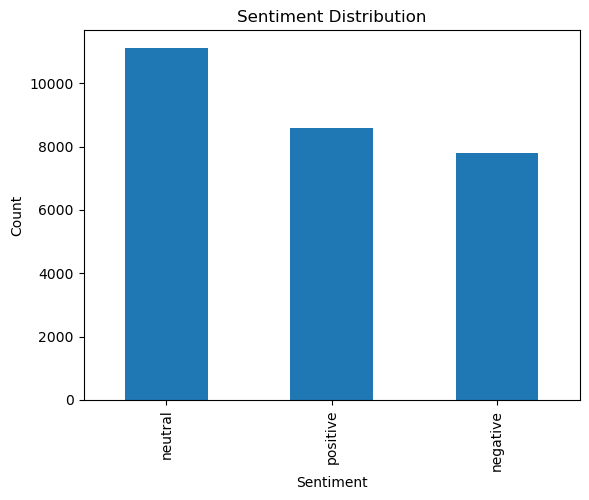

count    27480.000000
mean        68.330022
std         35.603870
min          3.000000
25%         39.000000
50%         64.000000
75%         97.000000
max        141.000000
Name: text_length, dtype: float64


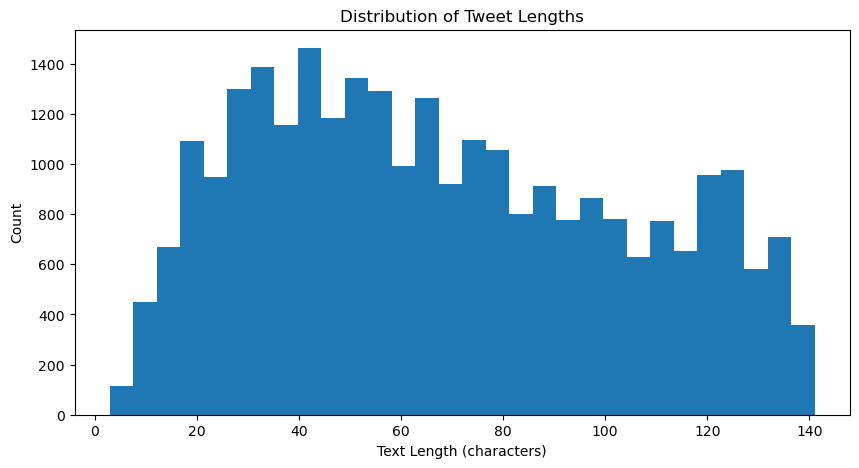

In [14]:
import matplotlib.pyplot as plt

print('Кількість класів:', df['sentiment'].nunique())
print('Класи:', df['sentiment'].unique())

print('\nКількість записів у кожному класі:')
print(df['sentiment'].value_counts())

df['sentiment'].value_counts().plot(kind='bar')

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()


df['text_length'] = df['text'].str.len()

print(df['text_length'].describe())

plt.figure(figsize=(10, 5))
plt.hist(df['text_length'], bins=30)

plt.title('Distribution of Tweet Lengths')
plt.xlabel('Text Length (characters)')
plt.ylabel('Count')
plt.show()

У наборі даних представлено 3 класи sentiment: neutral, positive та negative. Найбільше записів належить до класу neutral, але значного дисбалансу класів не спостерігається. Довжина твітів варіюється приблизно до 140 символів. Найбільше текстів мають довжину близько 30-60 символів, з піком приблизно в районі 40-45 символів.

### Завдання 3. Попередня обробка текстових даних та векторизація з bag of words


Наша задача тут отримати вектори методом bag of words колонки `text`, виконавши попередню обробку тексту.
Попередня обробка має включати
- видалення stopwords необхідної мови
- токенізація (розбиття текстів на фрагменти по 1 слову)
- стеммінг слів зі `SnowballStemmer`.
- самостійно задайте кількість слів в словнику для `sklearn.feature_extraction.text.CountVectorizer`. Можливо для цього доведеться виконати додатковий аналіз.

Ви також можете додати сюди додаткові методи очистки текстів, наприклад, видалення деяких символів чи груп символів, якщо в процесі роботи побачите, що хочете щось видалити.

Напишіть код аби виконати це завдання. Перед цим рекомендую детально ознайомитись з тим, що робить обʼєкт `sklearn.feature_extraction.text.CountVectorizer` за замовченням.

Це завдання можна виконати двома способами - один - максимально подібно до того, як ми це робили в лекції, другий - дещо інакше перегрупувавши етапи обробки тексту.




In [15]:
import re
import nltk
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))
stemmer = SnowballStemmer('english')

[nltk_data] Downloading package stopwords to C:\Users\Інна
[nltk_data]     Полякова\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [16]:
def tokenize_and_stem(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    
    tokens = text.split()
    
    tokens = [
        stemmer.stem(word)
        for word in tokens
        if word not in stop_words
    ]
    
    return tokens

In [17]:
print("Оригінальний текст:")
print(df['text'].iloc[0])

print("\nПісля обробки:")
print(tokenize_and_stem(df['text'].iloc[0]))

Оригінальний текст:
 I`d have responded, if I were going

Після обробки:
['respond', 'go']


In [18]:
vectorizer_full = CountVectorizer(
    tokenizer=tokenize_and_stem,
    token_pattern=None
)

X_full = vectorizer_full.fit_transform(df['text'])

print('Кількість слів у словнику:', len(vectorizer_full.vocabulary_))
print('Розмір матриці:', X_full.shape)

Кількість слів у словнику: 18596
Розмір матриці: (27480, 18596)


In [19]:
word_counts = np.asarray(X_full.sum(axis=0)).ravel()
words = vectorizer_full.get_feature_names_out()

word_freq = sorted(
    zip(words, word_counts),
    key=lambda x: x[1],
    reverse=True
)

print(word_freq[:20])

[('day', np.int64(2497)), ('go', np.int64(2384)), ('get', np.int64(1917)), ('good', np.int64(1600)), ('work', np.int64(1530)), ('love', np.int64(1486)), ('like', np.int64(1462)), ('today', np.int64(1155)), ('time', np.int64(1104)), ('got', np.int64(1099)), ('one', np.int64(1077)), ('lol', np.int64(1029)), ('happi', np.int64(1014)), ('want', np.int64(991)), ('thank', np.int64(990)), ('know', np.int64(980)), ('u', np.int64(971)), ('miss', np.int64(967)), ('back', np.int64(920)), ('realli', np.int64(916))]


In [20]:
print('Слів, що зустрічаються 1 раз:', np.sum(word_counts == 1))
print('Слів, що зустрічаються <= 2 разів:', np.sum(word_counts <= 2))
print('Слів, що зустрічаються <= 5 разів:', np.sum(word_counts <= 5))
print('Слів, що зустрічаються <= 10 разів:', np.sum(word_counts <= 10))

Слів, що зустрічаються 1 раз: 10561
Слів, що зустрічаються <= 2 разів: 12988
Слів, що зустрічаються <= 5 разів: 15308
Слів, що зустрічаються <= 10 разів: 16520


In [21]:
bow_vectorizer = CountVectorizer(
    tokenizer=tokenize_and_stem,
    token_pattern=None,
    max_features=5000
)

X_bow = bow_vectorizer.fit_transform(df['text'])

print('Розмір Bag of Words:', X_bow.shape)

Розмір Bag of Words: (27480, 5000)


Після попередньої обробки текстів було отримано словник із 18 596 токенів. Значна частина токенів зустрічалася дуже рідко: 10 561 - лише один раз. Тому для Bag of Words було обрано 5000 найбільш частотних токенів. У результаті отримано матрицю розміром (27480, 5000), де кожен рядок відповідає окремому твіту, а кожна колонка - токену зі словника.

### Завдання 4. Побудова класифікатора

- Розділіть індекси даних на навчальний та тестовий набори в обраному співвівдношенні. Використовуючи отримані індекси сфомуйте набори для тренування класифікатора `X_train_bow, X_test_bow, y_train, y_test`.
- Навчіть класифікатор (наприклад, Logistic Regression, Decision Tree або один з алгоритмів бустингу) на даних, векторизованих методом bag-of-words. Спробуйте кілька моделей і оберіть найбільш точну :)
- Виведіть інформацію, яка дає можливість оцінити якість класифікації.
- Оцініть якість фінальної класифікації: вона хороша чи не дуже?



In [22]:
y = df['sentiment'].values

In [23]:
from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
X_train_bow = X_bow[train_idx]
X_test_bow = X_bow[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

In [25]:
print('X_train:', X_train_bow.shape)
print('X_test:', X_test_bow.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (21984, 5000)
X_test: (5496, 5000)
y_train: (21984,)
y_test: (5496,)


In [26]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_bow, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [27]:
y_pred_lr = lr_model.predict(X_test_bow)

In [28]:
from sklearn.metrics import accuracy_score, classification_report

print('Accuracy:', accuracy_score(y_test, y_pred_lr))
print()
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.6875909752547307

              precision    recall  f1-score   support

    negative       0.70      0.63      0.66      1556
     neutral       0.63      0.71      0.67      2223
    positive       0.77      0.71      0.73      1717

    accuracy                           0.69      5496
   macro avg       0.70      0.68      0.69      5496
weighted avg       0.69      0.69      0.69      5496



In [29]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

dt_model.fit(X_train_bow, y_train)

y_pred_dt = dt_model.predict(X_test_bow)

print('Accuracy:', accuracy_score(y_test, y_pred_dt))
print()
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.6231804949053857

              precision    recall  f1-score   support

    negative       0.77      0.34      0.47      1556
     neutral       0.54      0.87      0.66      2223
    positive       0.80      0.56      0.66      1717

    accuracy                           0.62      5496
   macro avg       0.70      0.59      0.60      5496
weighted avg       0.69      0.62      0.61      5496



Було протестовано Logistic Regression та Decision Tree. Logistic Regression показала кращий результат з accuracy близько 0.69 порівняно з приблизно 0.62 для Decision Tree, тому її було обрано як фінальний класифікатор. Найкраще Logistic Regression класифікує позитивні тексти (F1-score = 0.73), тоді як для негативних і нейтральних класів F1-score становить 0.66 та 0.67 відповідно. Загалом якість класифікації можна оцінити як помірну: модель правильно класифікує близько 69% тестових прикладів, але все ще допускає помітну кількість помилок.

### Завдання 5. Аналіз впливовості слів в отриманого класифікатора

- Для обраної вами моделі проведіть аналіз важливості слів (ознак): які слова (токени) найбільше впливають для визначення сентименту? Чи це логічно на ваш погляд, що саме ці символи впливають найбільше/найменще?


In [30]:
import numpy as np

feature_names = bow_vectorizer.get_feature_names_out()

print('Класи:', lr_model.classes_)
print('Кількість слів:', len(feature_names))
print('Форма коефіцієнтів:', lr_model.coef_.shape)

for i, sentiment in enumerate(lr_model.classes_):
    
    coefficients = lr_model.coef_[i]
    
    top_indices = np.argsort(coefficients)[-10:][::-1]
    
    print(f'\nTop 10 words for {sentiment}:')
    
    for idx in top_indices:
        print(feature_names[idx], round(coefficients[idx], 3))

Класи: ['negative' 'neutral' 'positive']
Кількість слів: 5000
Форма коефіцієнтів: (3, 5000)

Top 10 words for negative:
sad 2.639
suck 2.498
sorri 2.437
bore 2.418
hate 2.324
fail 2.129
stupid 2.124
miss 2.08
worst 2.073
unfortun 1.987

Top 10 words for neutral:
indoor 1.63
chan 1.568
otherwis 1.278
parvo 1.255
oooo 1.24
sp 1.212
colorado 1.18
dd 1.166
twhirl 1.117
starwarsday 1.106

Top 10 words for positive:
cute 2.651
awesom 2.627
thank 2.43
love 2.395
glad 2.336
amaz 2.257
enjoy 2.122
nice 2.073
excit 2.068
bless 2.066


In [31]:
import numpy as np

feature_names = bow_vectorizer.get_feature_names_out()

for i, sentiment in enumerate(lr_model.classes_):
    
    coefficients = lr_model.coef_[i]
    
    least_indices = np.argsort(np.abs(coefficients))[:10]
    
    print(f'\n10 least influential words for {sentiment}:')
    
    for idx in least_indices:
        print(feature_names[idx], round(coefficients[idx], 4))


10 least influential words for negative:
hhaha 0.0
fewer 0.0
wizard 0.0
aj 0.0
cof 0.0
abc 0.0
chit 0.0
mulch 0.0
racoon 0.0
raft 0.0

10 least influential words for neutral:
chit 0.0
cof 0.0
mulch 0.0
hhaha 0.0
wizard 0.0
sana 0.0
fewer 0.0
raft 0.0
cameron 0.0
racoon 0.0

10 least influential words for positive:
chit 0.0
cof 0.0
aj 0.0
hhaha 0.0
racoon 0.0
mulch 0.0
abc 0.0
fewer 0.0
wizard 0.0
raft 0.0


Аналіз коефіцієнтів Logistic Regression показав, що найбільший вплив на визначення негативного сентименту мають слова sad, suck, sorri, hate, fail, worst, а позитивного - cute, awesom, thank, love, glad, amaz, enjoy, nice. Це логічно, оскільки ці слова мають виражене емоційне забарвлення. Для нейтрального класу найбільш впливові токени не мають такого очевидного емоційного забарвлення. Найменш впливові слова мають коефіцієнти, близькі до нуля (hhaha, wizard, mulch, racoon, raft тощо), тому практично не впливають на рішення моделі. Загалом отримані результати виглядають логічними та показують, що модель навчилася розпізнавати характерні слова для позитивного та негативного сентименту.

### Завдання 6. Векторизація текстів з допомогою TF-IDF. Тренування класифікатора, аналіз точності і впливовості слів.

- Проведіть векторизацію текстів з векторизатором TfidfVectorizer. Реалізуйте векторизацію так, аби препроцесинг включав всі ті самі кроки, що і в випадку використання векторизації Bag of Words.

- Натренуйте той самий класифікатор на TF-IDF векторах, виконавши розбивку набору даних на train, test так, аби в трейні були всі ті самі записи, що і були в попередньому завданні (це важливо для порівняння результатів).

- Проаналізуйте якість класифікації вивівши потрібні для цього метрики. Чи стала якість класифікації кращою?

- Які токени найбільше впливають на результат при тренуваннні класифікатора з TF-IDF векторами? Порівняйте з найважливішими токенами при Bag of Words векторизації. Яку векторизацію ви б обрали для фінальної імплементації рішення? Обґрунтуйте свій вибір.



In [32]:
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


tfidf_vectorizer = TfidfVectorizer(
    tokenizer=tokenize_and_stem,
    token_pattern=None,
    max_features=5000
)

X_tfidf = tfidf_vectorizer.fit_transform(df['text'])

print('Розмір TF-IDF:', X_tfidf.shape)


X_train_tfidf = X_tfidf[train_idx]
X_test_tfidf = X_tfidf[test_idx]

print('X_train TF-IDF:', X_train_tfidf.shape)
print('X_test TF-IDF:', X_test_tfidf.shape)


lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tfidf.fit(X_train_tfidf, y_train)


y_pred_tfidf = lr_tfidf.predict(X_test_tfidf)


bow_accuracy = accuracy_score(y_test, y_pred_lr)
tfidf_accuracy = accuracy_score(y_test, y_pred_tfidf)

print('\n--- TF-IDF RESULTS ---')
print('Accuracy:', tfidf_accuracy)
print()
print(classification_report(y_test, y_pred_tfidf))


print('\n--- COMPARISON ---')
print('Bag of Words Accuracy:', bow_accuracy)
print('TF-IDF Accuracy:', tfidf_accuracy)

if tfidf_accuracy > bow_accuracy:
    print('TF-IDF показав кращий результат.')
elif tfidf_accuracy < bow_accuracy:
    print('Bag of Words показав кращий результат.')
else:
    print('Результати однакові.')


feature_names_tfidf = tfidf_vectorizer.get_feature_names_out()

print('\n--- MOST IMPORTANT TF-IDF WORDS ---')

for i, sentiment in enumerate(lr_tfidf.classes_):
    
    coefficients = lr_tfidf.coef_[i]
    top_indices = np.argsort(coefficients)[-10:][::-1]
    
    print(f'\nTop 10 words for {sentiment}:')
    
    for idx in top_indices:
        print(
            feature_names_tfidf[idx],
            round(coefficients[idx], 3)
        )


feature_names_bow = bow_vectorizer.get_feature_names_out()

print('\n--- MOST IMPORTANT BAG OF WORDS WORDS ---')

for i, sentiment in enumerate(lr_model.classes_):
    
    coefficients = lr_model.coef_[i]
    top_indices = np.argsort(coefficients)[-10:][::-1]
    
    print(f'\nTop 10 words for {sentiment}:')
    
    for idx in top_indices:
        print(
            feature_names_bow[idx],
            round(coefficients[idx], 3)
        )

Розмір TF-IDF: (27480, 5000)
X_train TF-IDF: (21984, 5000)
X_test TF-IDF: (5496, 5000)

--- TF-IDF RESULTS ---
Accuracy: 0.6897743813682679

              precision    recall  f1-score   support

    negative       0.73      0.60      0.66      1556
     neutral       0.62      0.75      0.68      2223
    positive       0.78      0.68      0.73      1717

    accuracy                           0.69      5496
   macro avg       0.71      0.68      0.69      5496
weighted avg       0.70      0.69      0.69      5496


--- COMPARISON ---
Bag of Words Accuracy: 0.6875909752547307
TF-IDF Accuracy: 0.6897743813682679
TF-IDF показав кращий результат.

--- MOST IMPORTANT TF-IDF WORDS ---

Top 10 words for negative:
sad 5.251
miss 4.865
sorri 4.658
suck 4.323
hate 4.322
bore 3.935
fail 3.697
hurt 3.489
stupid 3.455
poor 3.351

Top 10 words for neutral:
indoor 1.309
guitar 1.239
except 1.113
moro 1.1
sp 1.033
differ 0.971
insur 0.965
otherwis 0.961
chan 0.955
starwarsday 0.944

Top 10 words for

Після векторизації текстів методом TF-IDF та навчання Logistic Regression було отримано accuracy приблизно 0.690, тоді як для Bag of Words accuracy становила близько 0.688. Таким чином, TF-IDF показав трохи кращий результат, хоча різниця між методами є незначною. F1-score для негативного, нейтрального та позитивного класів при TF-IDF становить 0.66, 0.68 та 0.73 відповідно.

Аналіз найбільш впливових токенів показав, що результати Bag of Words та TF-IDF багато в чому схожі. Для негативного сентименту обидва підходи виділяють такі слова, як sad, sorri, suck, hate, fail, а для позитивного - love, thank, awesom, amaz, enjoy, nice. Це логічно відповідає емоційному забарвленню цих класів.

Для фінальної реалізації я б обрала TF-IDF, оскільки він показав трохи вищу точність і, на відміну від Bag of Words, враховує не тільки частоту токена в тексті, а й те, наскільки цей токен є характерним для всього набору документів. Водночас перевага TF-IDF у цьому експерименті є невеликою.

### Завдання 7. Аналіз помилок класифікації з векторизацією TF-IDF.

- Проаналізуйте, на яких екземплярах помиляється класифікатор при векторизації TF-IDF.
- На основі аналізу запропонуйте 3 шляхи поліпшення якості класифікації.

In [33]:
import pandas as pd
from sklearn.metrics import confusion_matrix

test_texts = df.iloc[test_idx]['text'].values

errors_df = pd.DataFrame({
    'text': test_texts,
    'actual': y_test,
    'predicted': y_pred_tfidf
})

errors_df = errors_df[
    errors_df['actual'] != errors_df['predicted']
]

print('Кількість помилок:', len(errors_df))
print('Всього тестових прикладів:', len(y_test))

print('\nТипи помилок:')
print(
    errors_df.groupby(['actual', 'predicted'])
    .size()
    .sort_values(ascending=False)
)

print('\nПриклади помилок:')
print(errors_df.head(20).to_string(index=False))

Кількість помилок: 1705
Всього тестових прикладів: 5496

Типи помилок:
actual    predicted
negative  neutral      534
positive  neutral      478
neutral   negative     290
          positive     258
negative  positive      82
positive  negative      63
dtype: int64

Приклади помилок:
                                                                                                                      text   actual predicted
                                                           Reading and taking notes but undertanding none of it  ... HELP! negative   neutral
                        Hoping that this will just heal on it`s own because anything I put on it just makes it worse. Owww  neutral  negative
                                                                                              yum. Do you do home delivery positive   neutral
                                                    Having a wonderful piece of cake for lunch - what else could I want??? positive   neutral
     

Аналіз помилок TF-IDF класифікатора показав, що найчастіше модель помилково відносить негативні тексти до нейтральних (534 випадки) та позитивні до нейтральних (478 випадків). Значно рідше модель безпосередньо плутає позитивний і негативний сентимент: 82 випадки negative → positive та 63 випадки positive → negative. Отже, основною проблемою моделі є розмежування нейтрального та емоційно забарвленого тексту.

Для покращення якості класифікації можна: 1) додати біграми (ngram_range=(1, 2)), щоб модель враховувала не лише окремі слова, а й словосполучення та заперечення; 2) покращити preprocessing текстів, зокрема враховувати скорочення, заперечення, емодзі та інші характерні для твітів елементи, які можуть передавати емоційне забарвлення; 3) використати модель, яка враховує контекст і порядок слів, наприклад BERT, оскільки TF-IDF не розуміє значення речення як цілого.

І на фінал кернел для натхнення і ознайомлення з рішенням оригінальної задачі. Багато цікавих візуалізацій і аналізу є тут, а також тут розвʼязується саме проблема named entitty recognition і можна ознайомитись як це робиться - вона дещо складніша по своїй суті ніж класифікація, подумайте, чому:

https://www.kaggle.com/code/tanulsingh077/twitter-sentiment-extaction-analysis-eda-and-model